# 04 · Conclusiones

**Pregunta:** ¿cuántos meses de salario necesita un trabajador en Cuba para comprar
un panel solar y cómo ha evolucionado esa cifra?

Este notebook integra todo: salarios (ONEI), precios levantados en campo,
encuestas (n=25) e inflación. Cierra el proyecto.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
if not (RAIZ / 'data').exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import limpieza

FIGURAS = RAIZ / 'figures'
FIGURAS.mkdir(exist_ok=True)

## 1 · Salarios: nominal vs. real

`limpieza.salario_real()` pasa los pesos nominales a **pesos de 2025** usando el
índice encadenado de inflación (2020–2025). Los años 2016–2019 quedan en `NaN`
porque aún no tenemos sus variaciones de IPC.

In [2]:
salarios = limpieza.cargar('salarios_cuba.csv')
salarios['salario_real_2025'] = limpieza.salario_real(salarios)

print('Índice de precios (base 2025 = 100):')
print(limpieza.indice_ipc(2025).round(1).to_string())
print()
salarios[['anio', 'salario_medio_cup', 'salario_minimo_cup', 'salario_real_2025']]

Índice de precios (base 2025 = 100):
2020     21.7
2021     38.4
2022     53.4
2023     70.2
2024     87.6
2025    100.0



,anio,salario_medio_cup,salario_minimo_cup,salario_real_2025
0,2016,740,NaN,NaN
1,2017,767,NaN,NaN
2,2018,777,NaN,NaN
3,2019,879,NaN,NaN
4,2020,1194,NaN,5509.625290
5,2021,3849,NaN,10017.443743
6,2022,4209,NaN,7876.884405
7,2023,4654,NaN,6631.395243
8,2024,5839,NaN,6662.299000
9,2025,6930,NaN,6930.000000


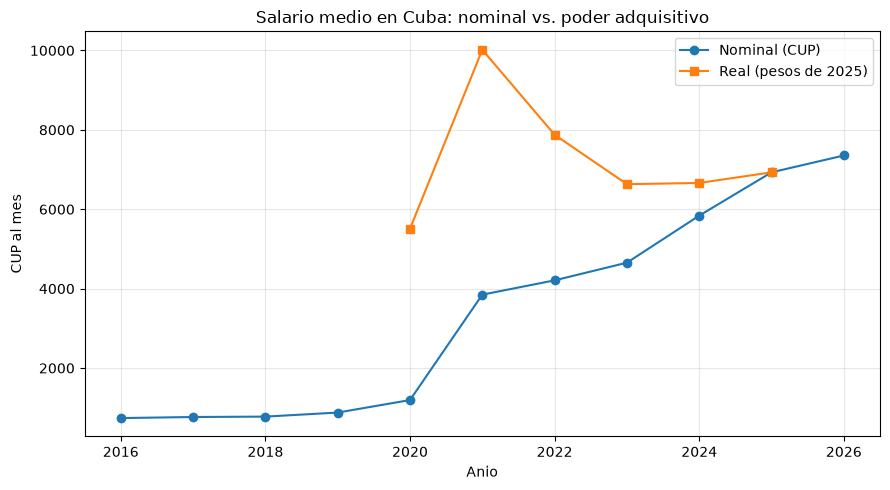

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(salarios['anio'], salarios['salario_medio_cup'], marker='o', label='Nominal (CUP)')
ax.plot(salarios['anio'], salarios['salario_real_2025'], marker='s', label='Real (pesos de 2025)')

ax.set_title('Salario medio en Cuba: nominal vs. poder adquisitivo')
ax.set_xlabel('Anio')
ax.set_ylabel('CUP al mes')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / 'salarios_nominal_vs_real.png', dpi=150)
plt.show()

In [4]:
real = salarios.dropna(subset=['salario_real_2025']).set_index('anio')['salario_real_2025']

print('2021 -> 2025: %.0f -> %.0f = %+.0f %% de poder adquisitivo' % (
    real[2021], real[2025], (real[2025] / real[2021] - 1) * 100))

sal_nom = salarios.set_index('anio')['salario_medio_cup']
infl_acum = 24.85  # acumulada 2026 hasta septiembre (ONEI)
real_2026 = sal_nom[2026] / (1 + infl_acum / 100)
print('2026 nominal %.0f (+%.1f%%) -> en pesos de 2025: %.0f (%+.1f%% vs 2025)' % (
    sal_nom[2026], (sal_nom[2026] / sal_nom[2025] - 1) * 100,
    real_2026, (real_2026 / sal_nom[2025] - 1) * 100))

2021 -> 2025: 10017 -> 6930 = -31 % de poder adquisitivo
2026 nominal 7354 (+6.1%) -> en pesos de 2025: 5890 (-15.0% vs 2025)


**Lectura:** el salario nominal subió ×1,8 entre 2021 y 2025, pero los precios
subieron ×2,6. El poder adquisitivo cayó ~31 %. En 2026 el salario sube en pesos
(+6,1 %) y baja en términos reales (≈ −15 % con la inflación acumulada).

## 2 · La métrica central: meses de salario

Se calcula para cada caso `precio ÷ salario medio del año de la observación`.
Se usan los precios registrados en `data/raw/precios_paneles.csv`.

In [5]:
precios = limpieza.precios_por_tipo()
sal_por_anio = salarios.set_index('anio')['salario_medio_cup']

precios['salario_medio'] = precios['anio'].map(sal_por_anio)
precios['meses_salario'] = precios['precio_estimado_cup'] / precios['salario_medio']

tabla = precios[['anio', 'tipo', 'potencia_wp', 'precio_estimado_cup',
                 'salario_medio', 'meses_salario', 'vendedor']].copy()
tabla['precio_estimado_cup'] = tabla['precio_estimado_cup'].round(0)
tabla['meses_salario'] = tabla['meses_salario'].round(1)
tabla

,anio,tipo,potencia_wp,precio_estimado_cup,salario_medio,meses_salario,vendedor
0,2021,sistema_sin_bateria,1000.0,55000.0,3849,14.3,Copextel
1,2026,modulo,800.0,75200.0,7354,10.2,UNE
2,2026,panel,550.0,146700.0,7354,19.9,mercado privado
3,2026,panel,535.0,146700.0,7354,19.9,mercado privado
4,2026,panel,615.0,211900.0,7354,28.8,mercado privado
5,2026,panel,625.0,128770.0,7354,17.5,mercado privado
6,2026,panel,225.0,81500.0,7354,11.1,mercado privado
7,2026,panel,500.0,154850.0,7354,21.1,mercado privado
8,2026,panel,580.0,163000.0,7354,22.2,mercado privado
9,2026,panel,600.0,110025.0,7354,15.0,mercado privado


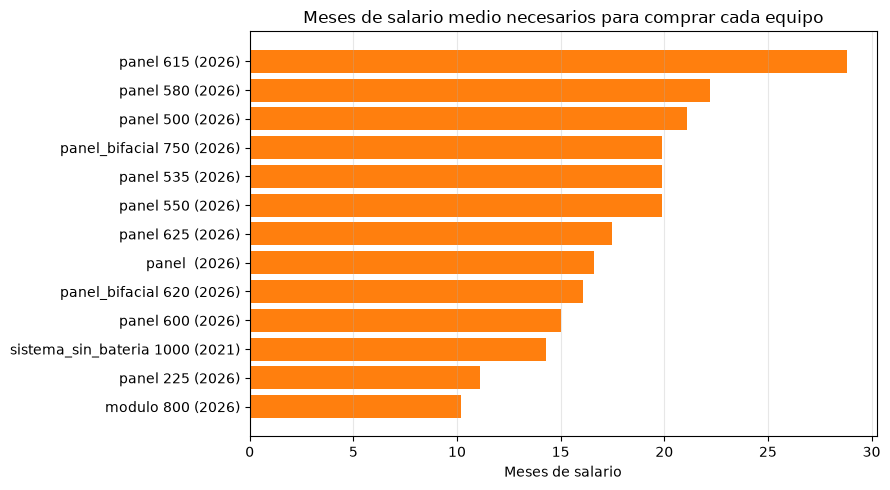

In [6]:
graficar = tabla[tabla['meses_salario'] <= 50].sort_values('meses_salario')

etiquetas = graficar.apply(
    lambda r: '%s %s (%d)' % (r['tipo'], '' if pd.isna(r['potencia_wp']) else int(r['potencia_wp']), r['anio']),
    axis=1,
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(etiquetas, graficar['meses_salario'], color='tab:orange')
ax.set_title('Meses de salario medio necesarios para comprar cada equipo')
ax.set_xlabel('Meses de salario')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURAS / 'meses_de_salario.png', dpi=150)
plt.show()

El **sistema completo de 5 kW** (2 530 000 CUP) queda fuera del gráfico: son
**~344 meses** (28 años de salario medio). Se comenta en el texto, no en el eje,
para no aplastar el resto de barras.

## 3 · Comparar bien: precio por vatio (CUP/Wp)

Comparar precios en bruto es una trampa: un panel de 225 W y uno de 620 W no son
lo mismo. La unidad común es el **precio por vatio**.

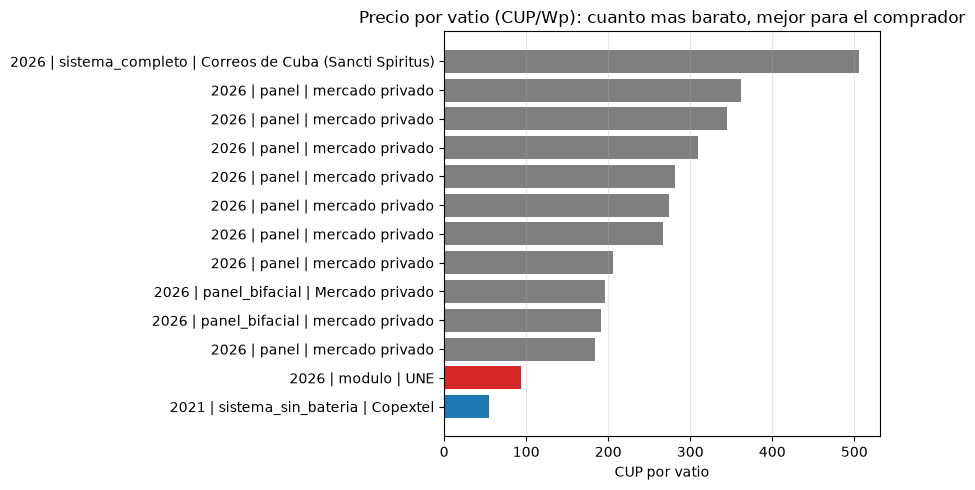

UNE oficial: 94 CUP/Wp
Mercado privado: mediana 270 CUP/Wp (rango 183 - 362)
El oficial es 65% mas barato por vatio.


In [7]:
wp = precios.dropna(subset=['precio_por_wp']).sort_values('precio_por_wp')

colores = wp['vendedor'].apply(
    lambda v: 'tab:red' if v == 'UNE' else ('tab:blue' if 'Copextel' in str(v) else 'tab:gray'))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(range(len(wp)), wp['precio_por_wp'], color=colores)
ax.set_yticks(range(len(wp)))
ax.set_yticklabels(['%d | %s | %s' % (r.anio, r.tipo, r.vendedor) for r in wp.itertuples()])
ax.set_title('Precio por vatio (CUP/Wp): cuanto mas barato, mejor para el comprador')
ax.set_xlabel('CUP por vatio')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURAS / 'precio_por_vatio.png', dpi=150)
plt.show()

une = wp[wp['vendedor'] == 'UNE']['precio_por_wp'].iloc[0]
privado = wp[wp['vendedor'].str.contains('privado', case=False, na=False)]['precio_por_wp']
print('UNE oficial: %.0f CUP/Wp' % une)
print('Mercado privado: mediana %.0f CUP/Wp (rango %.0f - %.0f)' % (
    privado.median(), privado.min(), privado.max()))
print('El oficial es %.0f%% mas barato por vatio.' % ((1 - une / privado.median()) * 100))

> **Aviso de método:** el precio del canal oficial se convierte con la cotización
> de mercado (815 CUP/USD). Si se usara la tasa oficial el resultado en pesos
> cambiaría: con un tipo de cambio provisional de 240 la comparación salía
> al revés. Por eso el CSV de tipo de cambio lleva su fuente y su fecha.

## 4 · Las encuestas: qué dice la gente

Resumen de `encuestas_percepcion.csv` (25 casos). El detalle está en el notebook 03.

In [8]:
encuestas = pd.read_csv(RAIZ / 'data' / 'raw' / 'encuestas_percepcion.csv')

economicos = ['El precio es imposible', 'El dinero', 'El salario']
obstaculo_ec = encuestas['obstaculo_principal'].isin(economicos).fillna(False)

con_respuesta = encuestas['tiempo_para_comprar'].notna().sum()
nunca = (encuestas['tiempo_para_comprar'] == 'Nunca podria comprarlo').sum()
sin_precio = encuestas['sabe_precio'].isin(['No lo sabia', 'He oido algo pero no se cifras']).sum()

print('Encuestas:', len(encuestas))
print('Obstaculo economico: %d/%d (%.0f%%)' % (
    obstaculo_ec.sum(), len(encuestas), obstaculo_ec.mean() * 100))
print('Dirian que nunca podrian comprarlo: %d/%d respondieron eso (%.0f%% de quienes contestaron)' % (
    nunca, con_respuesta, nunca / con_respuesta * 100))
print('No conocen el precio: %d/%d' % (sin_precio, encuestas['sabe_precio'].notna().sum()))

Encuestas: 25
Obstaculo economico: 17/25 (68%)
Dirian que nunca podrian comprarlo: 11/22 respondieron eso (50% de quienes contestaron)
No conocen el precio: 20/23


## 5 · Respuesta a la pregunta de investigación

**1. El kit solar del canal oficial cuesta 10,2 meses de salario medio 2026**
(75 200 ÷ 7 354) y 23,4 meses de salario mínimo (3 210).

**2. El panel del mercado privado cuesta entre 11 y 29 meses de salario medio**
según tamaño; la mediana (180 USD) son **19,9 meses**, y el sistema completo de
5 kW son ~344 meses.

**3. No hay "el precio del panel": hay un rango de 183 a 362 CUP/Wp.**
Comparar precios sin dividir entre vatios lleva a conclusiones falsas.

**4. El canal oficial es 65 % más barato por vatio, pero su acceso está restringido**
(trabajadores priorizados): el problema no es solo el precio, es quién puede comprarlo.

**5. La percepción y los números coinciden:** 44 % dice que nunca podría comprarlo
y 68 % señala el obstáculo económico, mientras el cálculo exige entre 10 y 29 meses
de salario entero. Además, el salario medio subió en pesos en 2026 y bajó
≈15 % en poder adquisitivo con una inflación acumulada del 24,85 %.

**Conclusión general:** en Cuba la energía solar no está limitada por la tecnología
sino por el ingreso y por el acceso al canal de venta.

## 6 · Limitaciones

1. **Muestra de encuesta no probabilística** (n=25, mayoría La Habana): no es
   representativa de Cuba.
2. **Índice de precios:** se usó una cadena de variaciones anuales 2020–2025; faltan
   2016–2019. El IPC oficial pondera el consumo de **2010** y mide solo mercado formal
   (Pavel Vidal estimó la inflación real 2025 ≈ 70 % incluyendo lo informal).
3. **Precios:** solo 2021 y 2026 con observaciones; no hay serie continua.
4. **Tipo de cambio:** 815 CUP/USD es cotización de mercado de campo, no tasa oficial.
5. **Encuesta:** dos instrumentos distintos y una pregunta con el vendedor mal indicado
   (Copextel/UNE) según los precios registrados.
6. Casos sin datos: E04, E06, E20, E24 (municipio o tiempo sin registrar).

## 7 · Pendientes del proyecto

| # | Pendiente | Para qué sirve |
|---|---|---|
| 1 | Variaciones de IPC **2016–2019** | deflactar toda la serie de salarios |
| 2 | **Índice IPC con base** (p. ej. dic-2015 = 100) | sustituir la cadena aproximada |
| 3 | Inflación 2026 completa (dic/dic) | cerrar el año real 2026 |
| 4 | Completar **citas** en `REFERENCIAS.md` | bibliografía exigible |
| 5 | Página/tabla exacta del ONEI por año | verificar los salarios |
| 6 | Potencia (W) del panel que costó 360 USD (E19) | un dato de precio perdido |

## 8 · Cierre

Fuentes completas en `REFERENCIAS.md`. Narrativa y guion de exposición en
`storytelling.md`. Gráficos exportados en `figures/`.

Toda fila de `data/raw/` lleva su fuente: **sin fuente no hay dato**.